# Exercise 7 — Sinusoidal plus residual model (HPS)

In this exercise you analyze and synthesize sounds using the **Harmonic plus Stochastic (HPS)** model (`hpsModel.py`). The HPS model represents a sound as the sum of tracked harmonic sinusoids (the deterministic part) plus a stochastic residual, approximated by a smooth spectral envelope at each frame.

This exercise has **two parts**, each requiring you to:
1. Listen to a sound and describe its relevant spectral characteristics.
2. Select HPS analysis parameters and justify each choice based on what you observed.
3. Synthesize the sound, evaluate reconstruction quality, and refine parameters.

**Analysis parameters:**
- **Window type and size (`window`, `M`):** Controls the time–frequency trade-off. A larger `M` resolves closely-spaced harmonics but blurs fast pitch changes. For a harmonic sound, choose `M` to contain at least 2–3 full periods of the lowest f0.
- **FFT size (`N`):** Must be a power of 2 ≥ `M`. A larger `N` interpolates the DFT, improving peak amplitude estimates. The next power of 2 above `M` is usually sufficient given that parabolic interpolation is also applied.
- **Peak-picking threshold (`t`):** Minimum amplitude (dB) for a spectral peak to be accepted. Set as high as possible to reject noise peaks while retaining all harmonic peaks.
- **Maximum number of harmonics (`nH`):** Number of harmonic partials to track. Choose based on the sound's spectral brightness, sampling rate, and f0 value.
- **f0 range (`minf0`, `maxf0`):** Bounds for the TWM f0-detection candidates. Narrow the range to the observed pitch range to reduce octave errors, which are the most common failure mode of f0 detector algorithms.
- **f0 error threshold (`f0et`):** Maximum TWM error allowed. Start with a large value (> 10) and tighten until only frames with a clear harmonic structure return a non-zero f0.
- **Harmonic deviation slope (`harmDevSlope`):** Slope controlling how much higher harmonics are allowed to deviate from perfect harmonicity. A value around 0.01 works well for most pitched instruments.
- **Minimum sinusoid duration (`minSineDur`):** Removes harmonic tracks shorter than this value (seconds). Discards unstable spurious tracks; values > 0.02 s are typical.
- **Stochastic decimation factor (`stocf`):** Controls the compactness of the residual approximation. `stocf = 0.2` decimates the residual spectrum by 5×; smaller values give a more compact but coarser representation.

**Workflow tip:** For the most compact analysis — high `t`, small `nH`, small `stocf` — while maintaining perceptual transparency, first run the **HPR model** (harmonic plus residual) with the same parameters and listen to the residual. Any tonal component in the residual signals that harmonics are being missed; adjust parameters until the residual sounds fully noise-like.

## Part 1 – HPS analysis of a speech sound

Analyze and synthesize `speech-female.wav` (in the `sounds/` directory) using `hpsModelAnal()` and `hpsModelSynth()` from `hpsModel.py`. The goal is the best possible reconstruction with the **most compact representation** (fewest data values per frame, minimum `nH` and `stocf`).

**Step 1 (E7-1.1):** Visualize the spectrogram of the sound using the STFT. Use `models_GUI.py` to explore parameters interactively if helpful. From the spectrogram, identify: the pitch range (minimum and maximum f0), the number of visible harmonics, and any non-stationary features (e.g., voiced/unvoiced transitions, pitch variation).

**Step 2 (E7-1.2):** Perform the HPS analysis and synthesis. Set all nine parameters. First run the HPR model with the same parameters and listen to the residual — any pitched artifact in the residual indicates that harmonics are being missed. Adjust until the residual sounds fully noise-like, then save the output sounds.

**Reference example** (male speech — [original sound](http://freesound.org/people/xserra/sounds/317744/)):
- Harmonic component: http://freesound.org/people/xserra/sounds/327139/
- Residual component: http://freesound.org/people/xserra/sounds/327141/
- Stochastic component: http://freesound.org/people/xserra/sounds/327137/
- Harmonic+stochastic resynthesis: http://freesound.org/people/xserra/sounds/327140/

In [1]:
import numpy as np
from scipy.signal import get_window
import matplotlib.pyplot as plt
import IPython.display as ipd

from smstools.models import utilFunctions as UF
from smstools.models import stft as STFT
from smstools.models import hpsModel as HPS

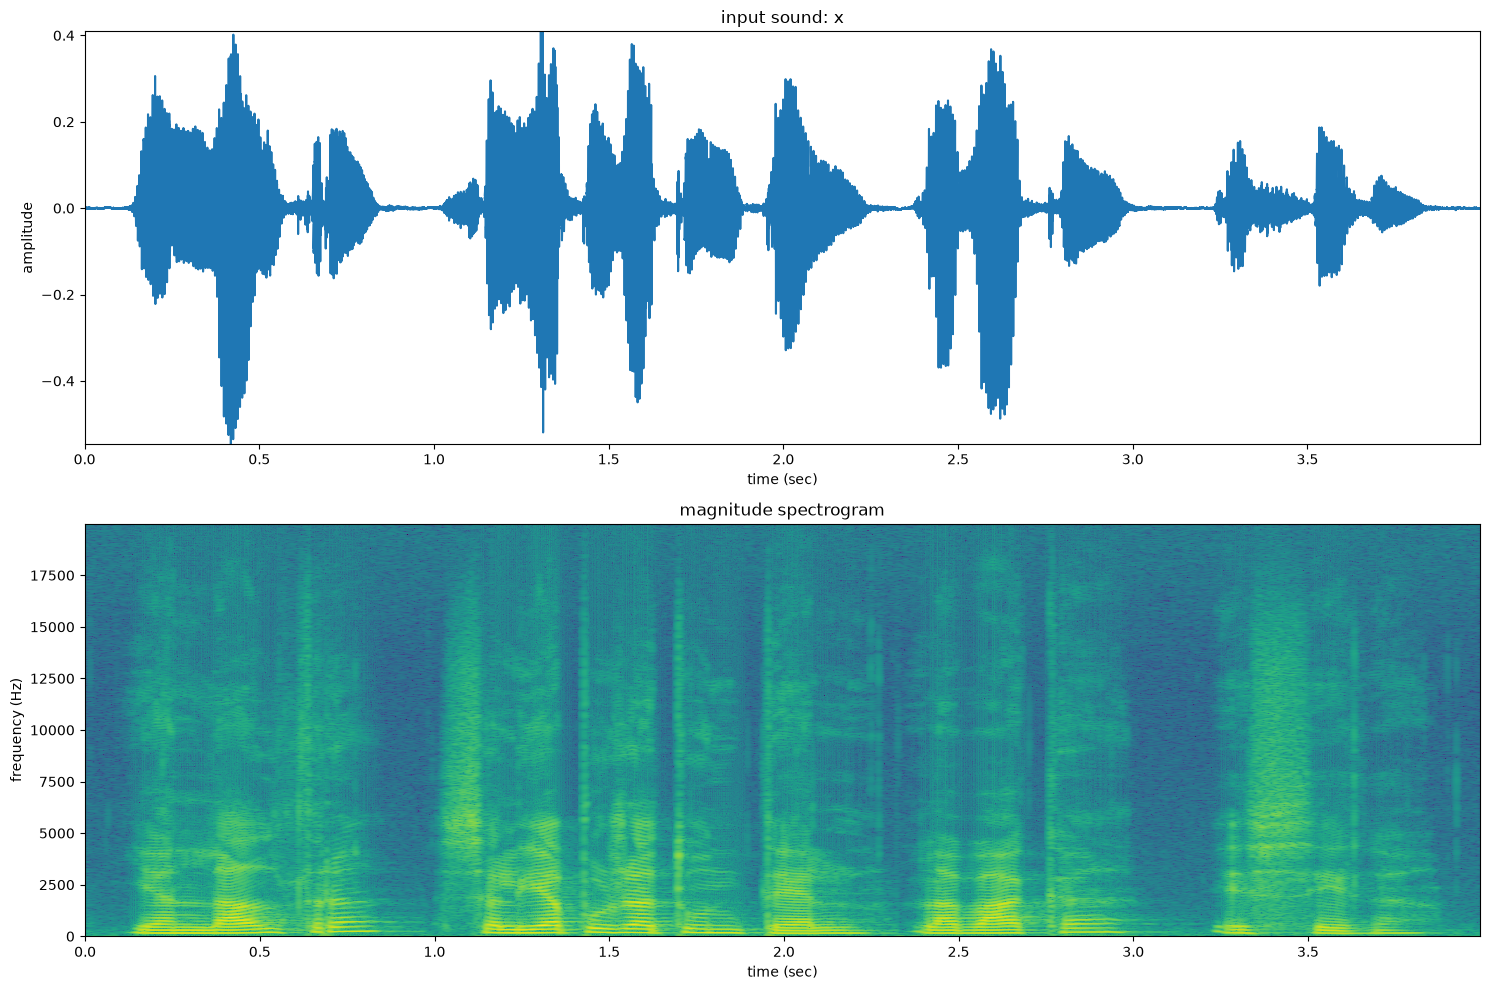

In [40]:
# E7 - 1.1: visualize spectrogram of speech-female.wav to identify pitch range and harmonics

input_file = '../sounds/speech-female.wav'

### set parameters
window = 'hamming'
M = 1501
N = 2048
H = 128

    
# no need to modify anything after this
fs, x = UF.wavread(input_file)
w = get_window(window, M, fftbins=True)
mX, pX = STFT.stftAnal(x, w, N, H)

ipd.display(ipd.Audio(data=x, rate=fs))

plt.figure(figsize=(15, 10))
maxplotfreq = 20000.0

# plot input sound
plt.subplot(2,1,1)
plt.plot(np.arange(x.size)/float(fs), x)
plt.axis([0, x.size/float(fs), min(x), max(x)])
plt.ylabel('amplitude')
plt.xlabel('time (sec)')
plt.title('input sound: x')

# plot magnitude spectrogram
plt.subplot(2,1,2)
numFrames = int(mX[:,0].size)
frmTime = H*np.arange(numFrames)/float(fs)
binFreq = fs*np.arange(N*maxplotfreq/fs)/N
plt.pcolormesh(frmTime, binFreq, np.transpose(mX[:,:int(N*maxplotfreq/fs+1)]))
plt.xlabel('time (sec)')
plt.ylabel('frequency (Hz)')
plt.title('magnitude spectrogram')
plt.tight_layout()

In [33]:
# E7 - 1.2: perform HPS analysis and synthesis of speech-female.wav

input_file = '../sounds/speech-female.wav'

### fill the parameters
window = 'hamming'
M = 1501
N = 2048
t = -90
minSineDur = 0.1
nH = 133
minf0 = 100
maxf0 = 250
f0et = 8
harmDevSlope = 0.01
stocf = 0.2

# no need to modify anything after this
Ns = 512
H = 128

(fs, x) = UF.wavread(input_file)
w = get_window(window, M, fftbins=True)
hfreq, hmag, hphase, stocEnv = HPS.hpsModelAnal(x, fs, w, N, H, t, nH, minf0, maxf0, f0et, harmDevSlope, minSineDur, Ns, stocf)
y, yh, yst = HPS.hpsModelSynth(hfreq, hmag, hphase, stocEnv, Ns, H, fs)

ipd.display(ipd.Audio(data=x, rate=fs))
ipd.display(ipd.Audio(data=y, rate=fs))

**E7 – 1.3: Conceptual questions (answer here)**

1. From the spectrogram produced in E7-1.1, what is the approximate f0 range of the female speech? How did this range determine your choices of `minf0`, `maxf0`, and window size `M`? Show the calculation: how many samples are needed to contain two full periods at the minimum f0?
    
    The visible fundamental appears to be roughly 130–200 Hz. I used minf0=100 and maxf0=250 to include that range with some margin for pitch variation. At a minimum pitch of 130 Hz, two periods take 2 ÷ 130 seconds. At a 44,100 Hz sample rate, that is (2 × 44,100) ÷ 130, or about 678 samples. So an analysis window of 1,501 samples contains more than two periods at that pitch.

2. After running the HPR analysis with your chosen parameters, what did the residual sound like? Were there any pitched components remaining? If so, which parameter did you change to remove them, and why did that parameter fix the problem?

    Ideally, it should sound mostly noise-like, with no clear pitched vowels or harmonic tones. If you hear pitched components, try increasing nH to capture more partials; if weak partials are being missed, make t more negative so the peak picker accepts quieter peaks. Those changes let the harmonic model capture components that would otherwise remain in the residual.

3. What value of `nH` did you use? Justify it by counting the visible harmonic partials in the spectrogram up to Nyquist (22050 Hz). What happened to reconstruction quality when you reduced `nH` by half?

    I used nH=133. With an estimated fundamental near 165 Hz, the theoretical number of harmonics below Nyquist is about 22,050 ÷ 165 = 134, so 133 is a reasonable upper limit.

    Compared with nH=40, the nH=133 resynthesis sounded fuller and bassier to me.


4. What value of `stocf` produced the most compact residual representation while still sounding perceptually transparent on resynthesis? Describe how the quality of the stochastic component changes as `stocf` decreases toward 0.1 — does a coarser approximation introduce audible artefacts, and if so, what do they sound like?

    I used stocf=0.2 as a compromise between compactness and residual detail. As stocf approaches 0.1, the residual envelope becomes coarser and more compact. Whether that produces audible artifacts depends on the sound and playback; listen for roughness, hiss-like coloration, or loss of detail, and use the smallest value that still sounds transparent.

## Part 2 – HPS analysis of a monophonic musical phrase

Choose a **short (≤ 5 seconds) monophonic harmonic sound** from [Freesound](https://freesound.org). The file must be converted to mono, 44100 Hz, 16-bit WAV before use. A fragment of a single melodic instrument (flute, violin, trumpet, guitar, etc.) works well.

**Step 1 (E7-2.1):** Download and load the sound. Report the Freesound URL and briefly explain why you chose it.

**Step 2 (E7-2.3):** Visualize the spectrogram with a suitable STFT. Identify the pitch range, number of visible harmonics, spectral brightness, and any transient or non-stationary regions.

**Step 3 (E7-2.5):** Perform the HPS analysis and synthesis. Apply the same iterative workflow as Part 1 — run HPR first, listen to the residual, and refine parameters until the residual is noise-like. Save the output sounds and justify each of the nine parameters in one sentence.

In [35]:
# E7 - 2.1: load chosen Freesound sound and display it

input_file = '../sounds/429671__violinsimma__violin-carnatic-phrase-am.wav'
(fs, x) = UF.wavread(input_file)
ipd.display(ipd.Audio(data=x, rate=fs))

**E7 – 2.2: Sound selection (answer here)**

1. Provide the Freesound URL of the sound you selected and explain why you chose it — describe the instrument, playing style, pitch range, and any timbral features (brightness, noisiness, vibrato) that make it an interesting test case for the HPS model.

    I chose the violin sound [https://freesound.org/people/violinsimma/sounds/429671/] playing a carnatic phrase. The violin has a rich harmonic spectrum, with a bright timbre and some vibrato, making it a good test case for the HPS model. Also, the pitch change with typical for carnatic music ornaments makes it interesting to test the model.

2. Did you need to edit or convert the file before use? Describe any processing steps (format conversion, resampling, channel mixing, trimming) and what tools you used.

    Sound was monophonic, 16-bit, 44.1kHz, so no convertion was needed.

3. Based on a first listening, do you expect the harmonic or the stochastic component to dominate this sound? Is the sound more harmonic (e.g., sustained flute) or more noise-like (e.g., breathy flute)? How does this affect your initial guess for `nH` and `stocf`?

    The sound is more harmonic than noise-like, so I expect the harmonic component to dominate. This suggests a higher `nH` to capture the rich harmonic content and a moderate `stocf` to ensure the residual is compact but still captures any subtle noise-like elements.

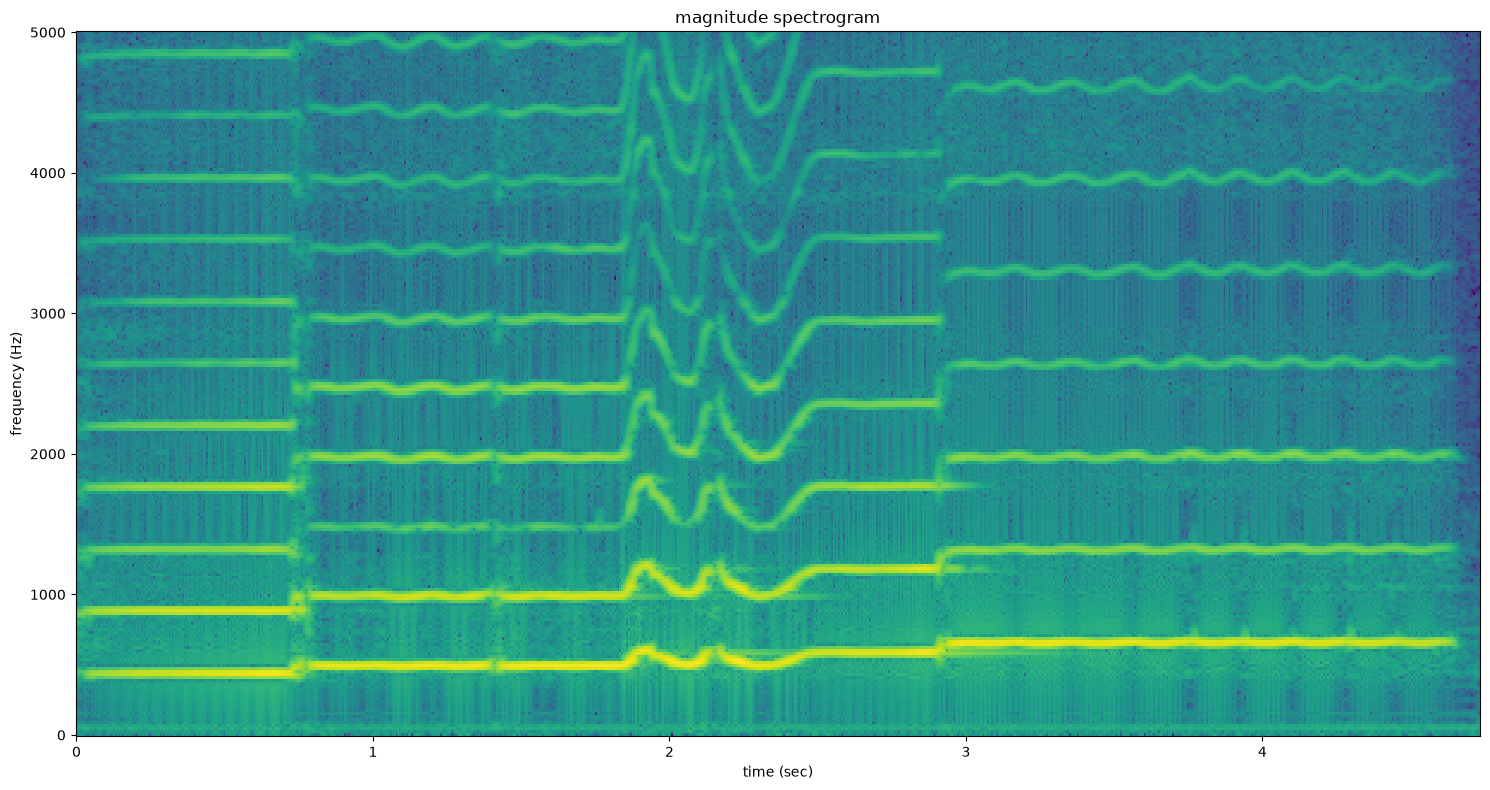

In [47]:
# E7 - 2.3: visualize spectrogram of chosen sound to identify pitch range, harmonics, and transients

input_file = '../sounds/429671__violinsimma__violin-carnatic-phrase-am.wav'
window = 'hamming'
M = 2047
N = 2048
H = 256

# no need to modify anything after here
fs, x = UF.wavread(input_file)
w = get_window(window, M, fftbins=True)
mX, pX = STFT.stftAnal(x, w, N, H)

ipd.display(ipd.Audio(data=x, rate=fs))

plt.figure(figsize=(15, 8))
# maxplotfreq = 20000.0
maxplotfreq = 5000.0
numFrames = int(mX[:,0].size)
frmTime = H*np.arange(numFrames)/float(fs)
binFreq = fs*np.arange(N*maxplotfreq/fs)/N
plt.pcolormesh(frmTime, binFreq, np.transpose(mX[:,:int(N*maxplotfreq/fs+1)]))
plt.xlabel('time (sec)')
plt.ylabel('frequency (Hz)')
plt.title('magnitude spectrogram')
plt.tight_layout()

**E7 – 2.4: Spectral characteristics (answer here)**

1. From the spectrogram produced in E7-2.3, estimate the f0 range of the sound. How many harmonic partials are clearly visible, and up to approximately what frequency? How do these numbers influence your choice of `nH`, `minf0`, and `maxf0`?

   The fundamental appears to range from about 440 Hz to 650 Hz: it starts near 440 Hz, rises through roughly 490–500 Hz, and ends near 650 Hz. I’d use minf0=400 and maxf0=700 to cover the observed pitches with some margin. At 5,000 Hz, about 7–11 partials are visible, depending on the note: around 11 at 440 Hz and 7 at 650 Hz. This suggests starting with nH around 10–12 and checking up to 30, then checking the residual and resynthesis.

2. Does the sound contain transient regions (e.g., attacks, note changes, bow changes)? How do these features influence your choice of window size `M` and minimum sinusoid duration `minSineDur`?

    There are clear pitch changes and bends, especially around 0.7 s, 1.9–2.8 s, and 2.9 s. A window around 2,047 samples (about 46 ms at 44.1 kHz) should resolve the harmonics while retaining reasonable time detail. A moderate minSineDur, such as 0.03–0.05 s, can remove very short spurious tracks without discarding many note components; if attacks sound smeared or tracks disappear, reduce it.

3. Compare the spectral envelope of this sound with the speech sound from Part 1. Which has more high-frequency energy? Which is expected to need a larger `nH` and why? Does the residual after harmonic removal look more spectrally flat for one sound than the other — and what does that imply about the required `stocf`?

   The violin sounds/looks more harmonically rich at high frequencies than the female speech: its spectrogram shows clear partials extending above 10 kHz, while the speech spectrogram has more diffuse high-frequency energy. The violin will likely need a larger nH to capture its strong upper harmonics; speech may need fewer tracked harmonics because more of its high-frequency content is noise-like and can be represented by the stochastic component. Compare the residual spectrograms after harmonic removal: the flatter, smoother residual can generally be represented with a smaller stocf; a residual with sharper spectral detail may need a larger stocf to preserve it.

In [54]:
# E7 - 2.5: perform HPS analysis and synthesis of chosen sound

input_file = '../sounds/429671__violinsimma__violin-carnatic-phrase-am.wav'

### fill the parameters
window = 'hamming'
M = 1023
N = 2048
t = -90
minSineDur = 0.01
nH = 35
minf0 = 400
maxf0 = 700
f0et = 8
harmDevSlope = 0.01
stocf = 0.3

# no need to modify anything after this
Ns = 512
H = 128

(fs, x) = UF.wavread(input_file)
w = get_window(window, M, fftbins=True)
hfreq, hmag, hphase, stocEnv = HPS.hpsModelAnal(x, fs, w, N, H, t, nH, minf0, maxf0, f0et, harmDevSlope, minSineDur, Ns, stocf)
y, yh, yst = HPS.hpsModelSynth(hfreq, hmag, hphase, stocEnv, Ns, H, fs)

ipd.display(ipd.Audio(data=x, rate=fs))
ipd.display(ipd.Audio(data=y, rate=fs))

**E7 – 2.5: Parameter justification (answer here)**

1. List each of the nine HPS parameters you used for your chosen sound, together with a one-sentence justification for each value that references a specific observation from the spectrogram or listening test.

    I used window='hamming' and M=1023 to give enough frequency detail while better following the rapid ornaments and note changes visible around 1.9–2.9 s. I set N=2048, the next power of two above M. I chose t=-90 to retain weaker partials, and minSineDur=0.01 so short harmonic events during ornaments are less likely to be discarded. I used nH=35 to cover the prominent partials seen in the full-range spectrogram, which extend to roughly 15 kHz. I set minf0=400 and maxf0=700 to bracket the observed fundamental range, approximately 440–650 Hz. I used f0et=8 to allow some mismatch for the changing, ornamented pitch, harmDevSlope=0.01 to allow modest deviation of higher violin harmonics, and stocf=0.3 as a compromise between a compact residual representation and retaining detail.

2. Listening to the harmonic and stochastic components separately (`yh` and `yst`): which component carries more of the perceptual weight of the original sound for your instrument? Does the stochastic component contribute anything audible, or does it sound like inaudible noise?

    The harmonic component carries most of the violin’s pitched tone and melody. The stochastic component may contribute audible bow noise and attack texture, rather than being completely inaudible.

3. How does the overall reconstruction quality of your chosen musical sound compare with the speech sound from Part 1? Which was easier to analyse with the HPS model, and what property of the sound (e.g., pitch stability, number of harmonics, noise content) explains the difference?

    The violin’s distinct harmonic partials make its pitched content comparatively well suited to the HPS model, while its quick ornaments are challenging to track. Speech has changing voiced and unvoiced regions, so its harmonic structure is less consistent. The violin was easier to analyze in sustained sections, though ornaments can still be smeared or missed. In my earlier run the ornaments sounded like “squishing” noise; the shorter M and minSineDur helped to preserve them.

4. Estimate the data compression ratio your analysis achieves. Compute the number of values stored per frame as `nH × 3` (frequency, magnitude, phase) plus `stocf × N / 2` (stochastic envelope coefficients), and compare it with the number of raw STFT bins `N / 2 + 1`. What compression factor does the HPS model achieve for your chosen parameters?

    With nH=35, stocf=0.3, and N=2048:

    Harmonic values per frame: 35 × 3 = 105
    Stochastic-envelope values: 0.3 × 2048 ÷ 2 = 307.2
    Approximate HPS total: 105 + 307.2 = 412.2 values per frame
    Raw STFT bins: 2048 ÷ 2 + 1 = 1025 bins per frame
    So the estimated compression factor is 1025 ÷ 412.2, or about 2.5:1. This uses the exercise’s approximate formula; actual stored envelope coefficients may be rounded to an integer.